In [1]:
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [2]:
DATA_PATH = "../data/raw/LC_loans_granting_model_dataset.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")

Dataset loaded successfully!
Rows: 1,347,681
Columns: 15


C:\Users\Ananya\AppData\Local\Temp\ipykernel_19784\2599870290.py:3: DtypeWarning: Columns (14: desc) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(DATA_PATH)


In [3]:
df.head()
df.tail()
df.sample(5, random_state=42)


,id,issue_d,revenue,dti_n,loan_amnt,fico_n,experience_c,emp_length,purpose,home_ownership_n,addr_state,zip_code,Default,title,desc
486099,77329604,Apr-2016,60000.0,13.22,5000,662.0,1,10+ years,debt_consolidation,MORTGAGE,OH,450xx,0,Debt consolidation,NaN
367342,38341768,Jan-2015,75000.0,11.78,30000,662.0,1,3 years,debt_consolidation,MORTGAGE,LA,700xx,1,Debt consolidation,NaN
234143,50627339,Jun-2015,91000.0,27.98,25000,727.0,1,1 year,debt_consolidation,OWN,TX,750xx,0,Debt consolidation,NaN
1239475,85734476,Jul-2016,94000.0,29.44,22825,662.0,1,10+ years,debt_consolidation,RENT,CA,913xx,1,NaN,NaN
1081157,3236952,Jul-2013,60000.0,18.66,26500,712.0,1,10+ years,debt_consolidation,MORTGAGE,AL,357xx,0,because I was stupid.,NaN


In [4]:
print("Number of columns:", len(df.columns))

for i, column in enumerate(df.columns, start=1):
    print(f"{i:3}. {column}")

Number of columns: 15
  1. id
  2. issue_d
  3. revenue
  4. dti_n
  5. loan_amnt
  6. fico_n
  7. experience_c
  8. emp_length
  9. purpose
 10. home_ownership_n
 11. addr_state
 12. zip_code
 13. Default
 14. title
 15. desc


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1347681 entries, 0 to 1347680
Data columns (total 15 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   id                1347681 non-null  int64  
 1   issue_d           1347681 non-null  str    
 2   revenue           1347681 non-null  float64
 3   dti_n             1347681 non-null  float64
 4   loan_amnt         1347681 non-null  int64  
 5   fico_n            1347681 non-null  float64
 6   experience_c      1347681 non-null  int64  
 7   emp_length        1347681 non-null  str    
 8   purpose           1347681 non-null  str    
 9   home_ownership_n  1347681 non-null  str    
 10  addr_state        1347681 non-null  str    
 11  zip_code          1347680 non-null  str    
 12  Default           1347681 non-null  int64  
 13  title             1331024 non-null  str    
 14  desc              119099 non-null   str    
dtypes: float64(3), int64(4), str(8)
memory usage: 154.2 MB


In [6]:
categorical_columns = df.select_dtypes(include=["object"]).columns

for column in categorical_columns:
    unique_count = df[column].nunique(dropna=False)

    if unique_count <= 20:
        print(f"\n--- {column} ---")
        print(df[column].value_counts(dropna=False))

C:\Users\Ananya\AppData\Local\Temp\ipykernel_19784\150625402.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include=["object"]).columns



--- emp_length ---
emp_length
10+ years    442667
2 years      122091
< 1 year     108517
3 years      107862
1 year        88841
5 years       84326
4 years       80761
NI            78188
6 years       62877
8 years       60808
7 years       59724
9 years       51019
Name: count, dtype: int64

--- purpose ---
purpose
debt_consolidation    781206
credit_card           295551
home_improvement       87684
other                  78263
major_purchase         29543
medical                15606
small_business         15575
car                    14647
moving                  9520
vacation                9083
house                   7294
wedding                 2350
renewable_energy         936
educational              423
Name: count, dtype: int64

--- home_ownership_n ---
home_ownership_n
MORTGAGE    666594
RENT        535585
OWN         144985
OTHER          517
Name: count, dtype: int64


In [7]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean() * 100
})

missing = missing.sort_values(
    "missing_percent",
    ascending=False
)

missing.head(30)

,missing_count,missing_percent
desc,1228582,91.162671
title,16657,1.235975
zip_code,1,0.000074
dti_n,0,0.000000
id,0,0.000000
issue_d,0,0.000000
revenue,0,0.000000
experience_c,0,0.000000
fico_n,0,0.000000
loan_amnt,0,0.000000


In [8]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate percentage:",
      round(df.duplicated().mean() * 100, 4), "%")

Duplicate rows: 0
Duplicate percentage: 0.0 %


In [11]:
print("Default distribution:")
print(df["Default"].value_counts())

print("\nDefault percentage:")
print(
    (df["Default"].value_counts(normalize=True) * 100)
    .round(2)
)

print("Default data type:", df["Default"].dtype)
print("Unique values:", sorted(df["Default"].unique()))

Default distribution:
Default
0    1078432
1     269249
Name: count, dtype: int64

Default percentage:
Default
0    80.02
1    19.98
Name: proportion, dtype: float64
Default data type: int64
Unique values: [np.int64(0), np.int64(1)]


In [12]:
print(df["issue_d"].value_counts().sort_index())
print("Earliest loan:", df["issue_d"].min())
print("Latest loan:", df["issue_d"].max())

issue_d
Apr-2008      259
Apr-2009      333
Apr-2010      912
Apr-2011     1563
Apr-2012     3230
            ...  
Sep-2014     9960
Sep-2015    25150
Sep-2016    16906
Sep-2017    13372
Sep-2018     2420
Name: count, Length: 139, dtype: int64
Earliest loan: Apr-2008
Latest loan: Sep-2018


In [13]:
numeric_columns = [
    "revenue",
    "dti_n",
    "loan_amnt",
    "fico_n",
    "experience_c"
]

df[numeric_columns].describe().T
df[numeric_columns].isna().sum()

revenue         0
dti_n           0
loan_amnt       0
fico_n          0
experience_c    0
dtype: int64

In [14]:
categorical_columns = [
    "emp_length",
    "purpose",
    "home_ownership_n",
    "addr_state"
]

for column in categorical_columns:
    print(f"\n===== {column} =====")
    print("Unique values:", df[column].nunique())
    print(df[column].value_counts().head(20))


===== emp_length =====
Unique values: 12
emp_length
10+ years    442667
2 years      122091
< 1 year     108517
3 years      107862
1 year        88841
5 years       84326
4 years       80761
NI            78188
6 years       62877
8 years       60808
7 years       59724
9 years       51019
Name: count, dtype: int64

===== purpose =====
Unique values: 14
purpose
debt_consolidation    781206
credit_card           295551
home_improvement       87684
other                  78263
major_purchase         29543
medical                15606
small_business         15575
car                    14647
moving                  9520
vacation                9083
house                   7294
wedding                 2350
renewable_energy         936
educational              423
Name: count, dtype: int64

===== home_ownership_n =====
Unique values: 4
home_ownership_n
MORTGAGE    666594
RENT        535585
OWN         144985
OTHER          517
Name: count, dtype: int64

===== addr_state =====
Unique value

In [15]:
print(df["experience_c"].value_counts(dropna=False))
pd.crosstab(
    df["experience_c"],
    df["Default"],
    normalize="index"
).round(4)

experience_c
1    1347656
0         25
Name: count, dtype: int64


Default,0,1
experience_c,,
0,0.8800,0.1200
1,0.8002,0.1998


In [16]:
print("Missing:", df["title"].isna().sum())
print("Unique titles:", df["title"].nunique())

df["title"].value_counts().head(30)

Missing: 16657
Unique titles: 61451


title
Debt consolidation           661113
Credit card refinancing      249854
Home improvement              75104
Other                         66746
Major purchase                24040
Debt Consolidation            16417
Medical expenses              13572
Business                      11769
Car financing                 11220
Vacation                       8059
Moving and relocation          7938
Home buying                    5894
Consolidation                  5678
debt consolidation             5084
Debt Consolidation Loan        3867
Credit Card Consolidation      2449
consolidation                  2268
Personal Loan                  2192
Home Improvement               1865
Consolidation Loan             1829
Credit Card Refinance          1505
Credit Card Payoff             1402
Consolidate                    1331
Personal                       1272
Loan                           1082
Debt                            844
Freedom                         838
personal              

In [17]:
## Target and Temporal Analysis
df["issue_year"] = pd.to_datetime(
    df["issue_d"],
    format="%b-%Y"
).dt.year

yearly_default = (
    df.groupby("issue_year")["Default"]
    .agg(
        total_loans="count",
        defaults="sum",
        default_rate="mean"
    )
    .reset_index()
)

yearly_default["default_rate"] *= 100

yearly_default

,issue_year,total_loans,defaults,default_rate
0,2007,599,158,26.377295
1,2008,2393,496,20.727121
2,2009,5281,723,13.690589
3,2010,12537,1757,14.014517
4,2011,21721,3297,15.178859
5,2012,53367,8644,16.197275
6,2013,134804,21024,15.595976
7,2014,223102,41161,18.449409
8,2015,375543,75802,20.184639
9,2016,293057,68229,23.281819


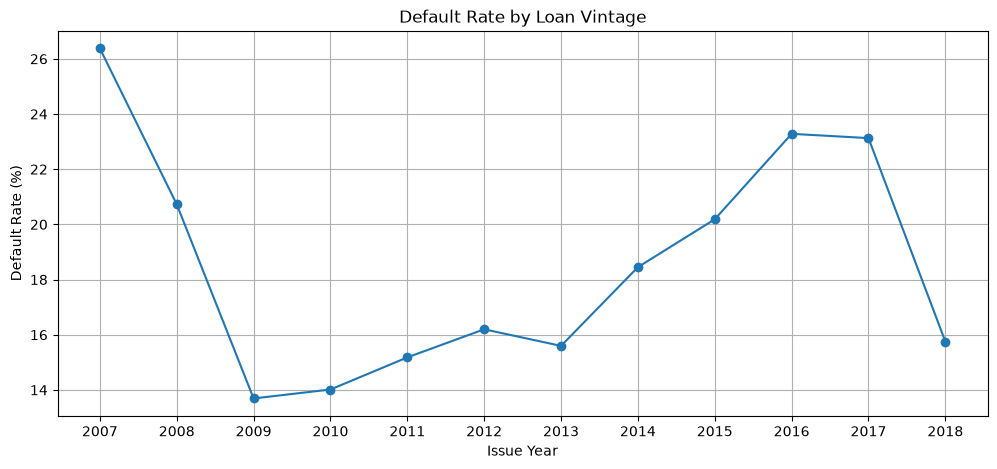

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    yearly_default["issue_year"],
    yearly_default["default_rate"],
    marker="o"
)

plt.xlabel("Issue Year")
plt.ylabel("Default Rate (%)")
plt.title("Default Rate by Loan Vintage")
plt.xticks(yearly_default["issue_year"])
plt.grid(True)

plt.show()

In [19]:
fico_default = (
    df.groupby("fico_n")["Default"]
    .agg(
        total_loans="count",
        default_rate="mean"
    )
    .reset_index()
)

fico_default["default_rate"] *= 100

fico_default.head(20)

,fico_n,total_loans,default_rate
0,612.0,2,0.000000
1,617.0,1,100.000000
2,622.0,1,0.000000
3,627.0,2,50.000000
4,632.0,6,66.666667
5,637.0,5,40.000000
6,642.0,102,28.431373
7,647.0,112,33.035714
8,652.0,131,29.007634
9,657.0,127,30.708661


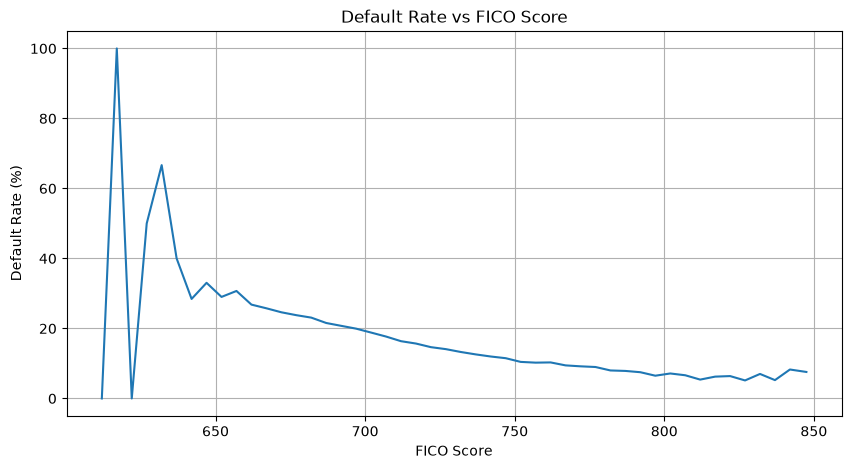

In [20]:
plt.figure(figsize=(10, 5))

plt.plot(
    fico_default["fico_n"],
    fico_default["default_rate"]
)

plt.xlabel("FICO Score")
plt.ylabel("Default Rate (%)")
plt.title("Default Rate vs FICO Score")
plt.grid(True)

plt.show()

In [21]:
df["dti_band"] = pd.cut(
    df["dti_n"],
    bins=[-np.inf, 10, 20, 30, 40, 50, np.inf],
    labels=[
        "<=10",
        "10-20",
        "20-30",
        "30-40",
        "40-50",
        ">50"
    ]
)

dti_default = (
    df.groupby("dti_band", observed=False)["Default"]
    .agg(
        total_loans="count",
        default_rate="mean"
    )
    .reset_index()
)

dti_default["default_rate"] *= 100

dti_default

,dti_band,total_loans,default_rate
0,<=10,245652,14.839285
1,10-20,563434,17.854265
2,20-30,409868,23.080114
3,30-40,121923,29.128220
4,40-50,4024,32.007952
5,>50,2780,28.741007


In [22]:
purpose_default = (
    df.groupby("purpose")["Default"]
    .agg(
        total_loans="count",
        default_rate="mean"
    )
    .sort_values("default_rate", ascending=False)
    .reset_index()
)

purpose_default["default_rate"] *= 100

purpose_default

,purpose,total_loans,default_rate
0,small_business,15575,29.855538
1,renewable_energy,936,23.717949
2,moving,9520,23.413866
3,house,7294,21.908418
4,medical,15606,21.844163
5,debt_consolidation,781206,21.154215
6,other,78263,21.084037
7,educational,423,20.803783
8,vacation,9083,19.189695
9,major_purchase,29543,18.603392


In [23]:
home_default = (
    df.groupby("home_ownership_n")["Default"]
    .agg(
        total_loans="count",
        default_rate="mean"
    )
    .reset_index()
)

home_default["default_rate"] *= 100

home_default

,home_ownership_n,total_loans,default_rate
0,MORTGAGE,666594,17.227128
1,OTHER,517,19.729207
2,OWN,144985,20.625582
3,RENT,535585,23.228432


In [24]:
fico_bins = [0, 620, 660, 700, 740, 780, 820, np.inf]

fico_labels = [
    "<620",
    "620-659",
    "660-699",
    "700-739",
    "740-779",
    "780-819",
    "820+"
]

df["fico_band"] = pd.cut(
    df["fico_n"],
    bins=fico_bins,
    labels=fico_labels,
    right=False
)

fico_band_default = (
    df.groupby("fico_band", observed=False)["Default"]
    .agg(
        total_loans="count",
        defaults="sum",
        default_rate="mean"
    )
    .reset_index()
)

fico_band_default["default_rate"] *= 100

fico_band_default

,fico_band,total_loans,defaults,default_rate
0,<620,3,1,33.333333
1,620-659,486,150,30.864198
2,660-699,822026,194006,23.600957
3,700-739,379874,61071,16.076646
4,740-779,106983,11303,10.565230
5,780-819,34307,2469,7.196782
6,820+,4002,249,6.221889


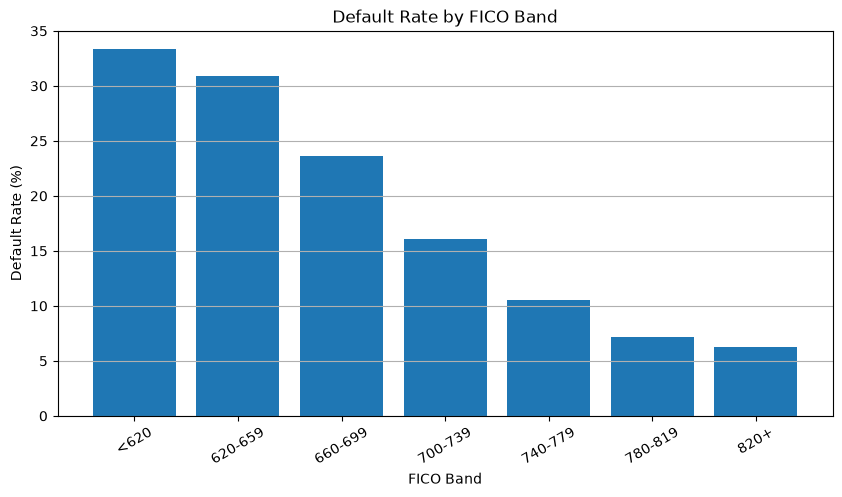

In [25]:
plt.figure(figsize=(10, 5))

plt.bar(
    fico_band_default["fico_band"].astype(str),
    fico_band_default["default_rate"]
)

plt.xlabel("FICO Band")
plt.ylabel("Default Rate (%)")
plt.title("Default Rate by FICO Band")
plt.xticks(rotation=30)
plt.grid(axis="y")

plt.show()

In [26]:
df[[
    "revenue",
    "dti_n",
    "loan_amnt",
    "fico_n"
]].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
revenue,1347681.0,77369.683174,70362.989597,1896.0,19000.0,28329.0,46600.00,65000.00,92000.00,160000.00,260000.00,10999200.0
dti_n,1347681.0,18.299091,11.152139,0.0,1.8,5.0,11.82,17.63,24.07,32.99,38.48,999.0
loan_amnt,1347681.0,14408.230490,8715.347372,500.0,1500.0,3200.0,7975.00,12000.00,20000.00,32800.00,35000.00,40000.0
fico_n,1347681.0,698.158922,31.848725,612.0,662.0,662.0,672.00,692.00,712.00,762.00,802.00,847.5


In [27]:
for column in ["revenue", "dti_n", "loan_amnt", "fico_n"]:
    print(f"\n===== {column} =====")
    print("Min:", df[column].min())
    print("Max:", df[column].max())
    print("Median:", df[column].median())


===== revenue =====
Min: 1896.0
Max: 10999200.0
Median: 65000.0

===== dti_n =====
Min: 0.0
Max: 999.0
Median: 17.63

===== loan_amnt =====
Min: 500
Max: 40000
Median: 12000.0

===== fico_n =====
Min: 612.0
Max: 847.5
Median: 692.0


In [28]:
df["loan_to_income"] = (
    df["loan_amnt"] / df["revenue"]
)
df["log_revenue"] = np.log1p(df["revenue"])
df["log_loan_amnt"] = np.log1p(df["loan_amnt"])


In [29]:
df["loan_to_income"].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
)
print(
    df["loan_to_income"]
    .replace([np.inf, -np.inf], np.nan)
    .isna()
    .sum()
)
df.groupby(
    pd.qcut(df["loan_to_income"], q=10, duplicates="drop")
)["Default"].mean() * 100


0


loan_to_income
(-0.000829, 0.0735]    12.677248
(0.0735, 0.107]        14.480215
(0.107, 0.137]         15.240765
(0.137, 0.167]         16.687963
(0.167, 0.197]         17.914727
(0.197, 0.228]         19.567104
(0.228, 0.266]         21.458055
(0.266, 0.311]         24.134155
(0.311, 0.37]          27.518639
(0.37, 1.338]          30.249763
Name: Default, dtype: float64

In [30]:
print("DTI = 999:", (df["dti_n"] == 999).sum())
print(
    "Percentage:",
    round((df["dti_n"] == 999).mean() * 100, 4),
    "%"
)
df.loc[df["dti_n"] == 999, "Default"].value_counts(
    normalize=True
) * 100
df.loc[
    df["dti_n"] == 999,
    ["revenue", "loan_amnt", "fico_n", "Default"]
].describe()

DTI = 999: 38
Percentage: 0.0028 %


,revenue,loan_amnt,fico_n,Default
count,38.000000,38.000000,38.000000,38.000000
mean,121625.026316,21169.078947,703.447368,0.236842
std,63820.668692,10625.414832,29.794519,0.430851
min,36020.000000,5000.000000,662.000000,0.000000
25%,67499.750000,10062.500000,678.250000,0.000000
50%,121000.000000,20750.000000,699.500000,0.000000
75%,158484.750000,29900.000000,722.000000,0.000000
max,243000.000000,40000.000000,777.000000,1.000000


In [31]:
df["log_revenue"] = np.log1p(df["revenue"])


In [32]:
print("DTI = 999:", (df["dti_n"] == 999).sum())
print(
    "Percentage:",
    round((df["dti_n"] == 999).mean() * 100, 4),
    "%"
)

DTI = 999: 38
Percentage: 0.0028 %


In [33]:
print(
    df.loc[
        df["dti_n"] == 999,
        "Default"
    ].value_counts(normalize=True) * 100
)

Default
0    76.315789
1    23.684211
Name: proportion, dtype: float64


In [34]:
df.loc[
    df["dti_n"] == 999,
    ["revenue", "loan_amnt", "fico_n", "emp_length",
     "purpose", "home_ownership_n", "Default"]
].head(20)

,revenue,loan_amnt,fico_n,emp_length,purpose,home_ownership_n,Default
7767,62151.0,6550,672.0,NI,credit_card,MORTGAGE,0
381305,78800.0,8000,687.0,1 year,debt_consolidation,MORTGAGE,0
386273,66633.0,10250,712.0,3 years,debt_consolidation,MORTGAGE,0
394079,126665.0,14225,752.0,NI,home_improvement,OWN,0
398115,58800.0,15000,717.0,NI,debt_consolidation,MORTGAGE,0
398172,153000.0,26000,762.0,NI,debt_consolidation,MORTGAGE,0
402650,76000.0,21000,692.0,NI,debt_consolidation,MORTGAGE,0
404149,138100.0,10000,722.0,< 1 year,debt_consolidation,MORTGAGE,0
411443,160300.0,35000,672.0,NI,debt_consolidation,MORTGAGE,0
417509,145600.0,35000,677.0,NI,debt_consolidation,RENT,1


In [35]:
print(
    df["dti_n"]
    .sort_values(ascending=False)
    .head(30)
    .to_list()
)

[999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0]


In [36]:
model_df = df.copy()

print(model_df.shape)

(1347681, 21)


In [37]:
model_df["dti_n"] = model_df["dti_n"].replace(999, np.nan)

print("Missing DTI:", model_df["dti_n"].isna().sum())

Missing DTI: 38


In [38]:
model_df["issue_date"] = pd.to_datetime(
    model_df["issue_d"],
    format="%b-%Y"
)

model_df["issue_year"] = model_df["issue_date"].dt.year
model_df["issue_month"] = model_df["issue_date"].dt.month

model_df[
    ["issue_d", "issue_date", "issue_year", "issue_month"]
].head()

,issue_d,issue_date,issue_year,issue_month
0,Dec-2015,2015-12-01,2015,12
1,Dec-2015,2015-12-01,2015,12
2,Dec-2015,2015-12-01,2015,12
3,Dec-2015,2015-12-01,2015,12
4,Dec-2015,2015-12-01,2015,12


In [39]:
model_df["loan_to_income"] = (
    model_df["loan_amnt"] / model_df["revenue"]
)
model_df["loan_to_income"].describe()

count    1.347681e+06
mean     2.105219e-01
std      1.124879e-01
min      1.714286e-04
25%      1.228102e-01
50%      1.966292e-01
75%      2.857143e-01
max      1.337500e+00
Name: loan_to_income, dtype: float64

In [40]:
model_df["log_revenue"] = np.log1p(model_df["revenue"])

model_df["log_loan_amnt"] = np.log1p(
    model_df["loan_amnt"]
)

In [41]:
def convert_emp_length(value):
    if value == "NI":
        return np.nan
    elif value == "< 1 year":
        return 0
    elif value == "10+ years":
        return 10
    else:
        return int(value.split()[0])


model_df["employment_years"] = (
    model_df["emp_length"]
    .apply(convert_emp_length)
)

model_df[
    ["emp_length", "employment_years"]
].drop_duplicates().sort_values(
    "employment_years"
)

,emp_length,employment_years
23,< 1 year,0.0
28,1 year,1.0
18,2 years,2.0
3,3 years,3.0
4,4 years,4.0
21,5 years,5.0
7,6 years,6.0
10,7 years,7.0
12,8 years,8.0
22,9 years,9.0


In [42]:
model_df["experience_c"].value_counts()

experience_c
1    1347656
0         25
Name: count, dtype: int64

In [43]:
drop_columns = [
    "id",
    "issue_d",
    "issue_date",
    "experience_c",
    "emp_length",
    "zip_code",
    "title",
    "desc"
]

model_df = model_df.drop(
    columns=drop_columns
)

In [44]:
print(model_df.shape)
print(model_df.columns.tolist())

(1347681, 16)
['revenue', 'dti_n', 'loan_amnt', 'fico_n', 'purpose', 'home_ownership_n', 'addr_state', 'Default', 'issue_year', 'dti_band', 'fico_band', 'loan_to_income', 'log_revenue', 'log_loan_amnt', 'issue_month', 'employment_years']


In [45]:
model_df.isna().sum().sort_values(
    ascending=False
)

employment_years    78188
dti_n                  38
loan_amnt               0
revenue                 0
purpose                 0
home_ownership_n        0
addr_state              0
fico_n                  0
Default                 0
issue_year              0
fico_band               0
dti_band                0
loan_to_income          0
log_revenue             0
log_loan_amnt           0
issue_month             0
dtype: int64

In [46]:
train_df = model_df[
    model_df["issue_year"] <= 2015
].copy()

val_df = model_df[
    model_df["issue_year"] == 2016
].copy()

test_df = model_df[
    model_df["issue_year"] >= 2017
].copy()
print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)
print(
    train_df["issue_year"].min(),
    train_df["issue_year"].max()
)

print(
    val_df["issue_year"].min(),
    val_df["issue_year"].max()
)

print(
    test_df["issue_year"].min(),
    test_df["issue_year"].max()
)

Train: (829347, 16)
Validation: (293057, 16)
Test: (225277, 16)
2007 2015
2016 2016
2017 2018


In [47]:
for name, data in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(
        name,
        "rows =", len(data),
        "| default rate =",
        round(data["Default"].mean() * 100, 2),
        "%"
    )

Train rows = 829347 | default rate = 18.46 %
Validation rows = 293057 | default rate = 23.28 %
Test rows = 225277 | default rate = 21.29 %


In [48]:
eda_only_columns = [
    "dti_band",
    "fico_band"
]

model_df = model_df.drop(
    columns=eda_only_columns
)

print(model_df.columns.tolist())
print(model_df.shape)

['revenue', 'dti_n', 'loan_amnt', 'fico_n', 'purpose', 'home_ownership_n', 'addr_state', 'Default', 'issue_year', 'loan_to_income', 'log_revenue', 'log_loan_amnt', 'issue_month', 'employment_years']
(1347681, 14)


In [49]:
train_df = model_df[
    model_df["issue_year"] <= 2015
].copy()

val_df = model_df[
    model_df["issue_year"] == 2016
].copy()

test_df = model_df[
    model_df["issue_year"] >= 2017
].copy()

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (829347, 14)
Validation: (293057, 14)
Test: (225277, 14)


In [50]:
target = "Default"

feature_columns = [
    "revenue",
    "dti_n",
    "loan_amnt",
    "fico_n",
    "purpose",
    "home_ownership_n",
    "addr_state",
    "loan_to_income",
    "log_revenue",
    "log_loan_amnt",
    "employment_years"
]

X_train = train_df[feature_columns]
y_train = train_df[target]

X_val = val_df[feature_columns]
y_val = val_df[target]

X_test = test_df[feature_columns]
y_test = test_df[target]

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (829347, 11)
X_val: (293057, 11)
X_test: (225277, 11)


In [51]:
numeric_features = [
    "revenue",
    "dti_n",
    "loan_amnt",
    "fico_n",
    "loan_to_income",
    "log_revenue",
    "log_loan_amnt",
    "employment_years"
]
categorical_features = [
    "purpose",
    "home_ownership_n",
    "addr_state"
]

In [59]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(
    zip(classes, weights)
)

class_weights

{np.int64(0): np.float64(0.6131638288591348),
 np.int64(1): np.float64(2.709186473455201)}

In [61]:
# Recreate issue_month
df["issue_month"] = df["issue_d"].str[:3].map({
    "Jan": 1,
    "Feb": 2,
    "Mar": 3,
    "Apr": 4,
    "May": 5,
    "Jun": 6,
    "Jul": 7,
    "Aug": 8,
    "Sep": 9,
    "Oct": 10,
    "Nov": 11,
    "Dec": 12
})

# Recreate employment_years
emp_map = {
    "< 1 year": 0,
    "1 year": 1,
    "2 years": 2,
    "3 years": 3,
    "4 years": 4,
    "5 years": 5,
    "6 years": 6,
    "7 years": 7,
    "8 years": 8,
    "9 years": 9,
    "10+ years": 10,
    "NI": np.nan
}

df["employment_years"] = df["emp_length"].map(emp_map)

print(df[["issue_d", "issue_month", "emp_length", "employment_years"]].head())
print("\nMissing employment_years:", df["employment_years"].isna().sum())

    issue_d  issue_month emp_length  employment_years
0  Dec-2015           12  10+ years              10.0
1  Dec-2015           12  10+ years              10.0
2  Dec-2015           12  10+ years              10.0
3  Dec-2015           12    3 years               3.0
4  Dec-2015           12    4 years               4.0

Missing employment_years: 78188


In [63]:
print(df.columns.tolist())

['id', 'issue_d', 'revenue', 'dti_n', 'loan_amnt', 'fico_n', 'experience_c', 'emp_length', 'purpose', 'home_ownership_n', 'addr_state', 'zip_code', 'Default', 'title', 'desc', 'issue_year', 'dti_band', 'fico_band', 'loan_to_income', 'log_revenue', 'log_loan_amnt', 'issue_month', 'employment_years']


In [62]:
target = "Default"

features = [
    "revenue",
    "dti_n",
    "loan_amnt",
    "fico_n",
    "purpose",
    "home_ownership_n",
    "addr_state",
    "issue_year",
    "loan_to_income",
    "log_revenue",
    "log_loan_amnt",
    "issue_month",
    "employment_years"
]

X = df[features].copy()
y = df[target].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1347681, 13)
y shape: (1347681,)


In [64]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = [
    "revenue",
    "dti_n",
    "loan_amnt",
    "fico_n",
    "issue_year",
    "loan_to_income",
    "log_revenue",
    "log_loan_amnt",
    "issue_month",
    "employment_years"
]

categorical_features = [
    "purpose",
    "home_ownership_n",
    "addr_state"
]

In [65]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [66]:
X_train = train_df[features]
y_train = train_df[target]

X_val = val_df[features]
y_val = val_df[target]

X_test = test_df[features]
y_test = test_df[target]

In [67]:
print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(829347, 13)
(293057, 13)
(225277, 13)


In [68]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        class_weight=class_weights,
        max_iter=1000,
        solver="saga",
        n_jobs=-1
    ))
])

In [69]:
logistic_model.fit(X_train, y_train)

c:\Users\Ananya\OneDrive\Documents\Visual Studio Code\credit-risk-loan-default\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\Ananya\OneDrive\Documents\Visual Studio Code\credit-risk-loan-default\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['revenue','dti_n','loan_amnt',...,'log_loan_amnt','issue_month', 'employment_years']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passth

In [ ]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    classification_report
)

val_prob = logistic_model.predict_proba(X_val)[:, 1]

val_pred = (val_prob >= 0.5).astype(int)

roc_auc = roc_auc_score(y_val, val_prob)
pr_auc = average_precision_score(y_val, val_prob)
f1 = f1_score(y_val, val_pred)

print("Logistic Regression")
print("-------------------")
print(f"ROC-AUC : {roc_auc:.4f}")
print(f"PR-AUC  : {pr_auc:.4f}")
print(f"F1      : {f1:.4f}")

print(classification_report(y_val, val_pred))

Logistic Regression
-------------------
ROC-AUC : 0.6650
PR-AUC  : 0.3625
F1      : 0.4312
              precision    recall  f1-score   support

           0       0.85      0.57      0.68    224828
           1       0.32      0.66      0.43     68229

    accuracy                           0.59    293057
   macro avg       0.58      0.62      0.56    293057
weighted avg       0.73      0.59      0.62    293057



In [76]:
X_train_processed = preprocessor.transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print(X_train_processed.shape)
print(X_val_processed.shape)
print(X_test_processed.shape)

(829347, 79)
(293057, 79)
(225277, 79)


In [77]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    classification_report
)

rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=50,
    class_weight=class_weights,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train_processed, y_train)

rf_prob = rf.predict_proba(X_val_processed)[:, 1]
rf_pred = (rf_prob >= 0.5).astype(int)

print("Random Forest")
print("-------------------")
print(f"ROC-AUC : {roc_auc_score(y_val, rf_prob):.4f}")
print(f"PR-AUC  : {average_precision_score(y_val, rf_prob):.4f}")
print(f"F1      : {f1_score(y_val, rf_pred):.4f}")
print()
print(classification_report(y_val, rf_pred))

Random Forest
-------------------
ROC-AUC : 0.6604
PR-AUC  : 0.3590
F1      : 0.4248

              precision    recall  f1-score   support

           0       0.84      0.62      0.71    224828
           1       0.33      0.61      0.42     68229

    accuracy                           0.61    293057
   macro avg       0.58      0.61      0.57    293057
weighted avg       0.72      0.61      0.64    293057



In [78]:
preprocessor.fit_transform(X_train)
preprocessor.transform(X_val)
preprocessor.transform(X_test)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 2928601 stored elements and shape (225277, 79)>

In [79]:
import xgboost as xgb

print(xgb.__version__)

3.4.1


In [80]:
from xgboost import XGBClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    classification_report
)

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_processed, y_train)

xgb_prob = xgb_model.predict_proba(X_val_processed)[:, 1]
xgb_pred = (xgb_prob >= 0.5).astype(int)

print("XGBoost")
print("-------------------")
print(f"ROC-AUC : {roc_auc_score(y_val, xgb_prob):.4f}")
print(f"PR-AUC  : {average_precision_score(y_val, xgb_prob):.4f}")
print(f"F1      : {f1_score(y_val, xgb_pred):.4f}")
print()
print(classification_report(y_val, xgb_pred))

XGBoost
-------------------
ROC-AUC : 0.6709
PR-AUC  : 0.3706
F1      : 0.4343

              precision    recall  f1-score   support

           0       0.85      0.59      0.69    224828
           1       0.32      0.65      0.43     68229

    accuracy                           0.60    293057
   macro avg       0.59      0.62      0.56    293057
weighted avg       0.73      0.60      0.63    293057



In [81]:
from sklearn.metrics import brier_score_loss

xgb_brier = brier_score_loss(y_val, xgb_prob)

print(f"XGBoost Brier Score: {xgb_brier:.4f}")

XGBoost Brier Score: 0.2315


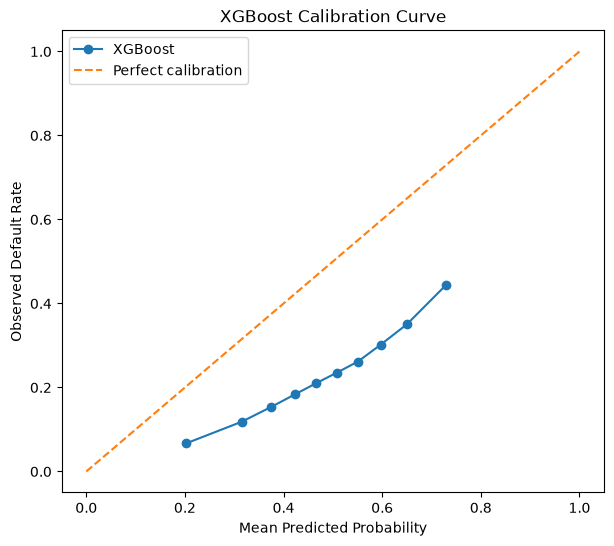

In [82]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

prob_true, prob_pred = calibration_curve(
    y_val,
    xgb_prob,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 6))

plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="XGBoost"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Default Rate")
plt.title("XGBoost Calibration Curve")
plt.legend()
plt.show()

In [83]:
xgb_test_prob = xgb_model.predict_proba(X_test_processed)[:, 1]

print(xgb_test_prob.min())
print(xgb_test_prob.max())

0.01867173
0.8853016


In [84]:
from sklearn.isotonic import IsotonicRegression

calibrator = IsotonicRegression(
    y_min=0,
    y_max=1,
    out_of_bounds="clip"
)

calibrator.fit(xgb_prob, y_val)

,"y_min y_min: float, default=NoneLower bound on the lowest predicted value (the minimum value maystill be higher). If not set, defaults to -inf.",0
,"y_max y_max: float, default=NoneUpper bound on the highest predicted value (the maximum may still belower). If not set, defaults to +inf.",1
,"out_of_bounds out_of_bounds: {'nan', 'clip', 'raise'}, default='nan'Handles how `X` values outside of the training domain are handledduring prediction.- 'nan', predictions will be NaN.- 'clip', predictions will be set to the value corresponding to the nearest train interval endpoint.- 'raise', a `ValueError` is raised.",'clip'
,"increasing increasing: bool or 'auto', default=TrueDetermines whether the predictions should be constrained to increaseor decrease with `X`. 'auto' will decide based on the Spearmancorrelation estimate's sign.",True
Name,Type,Value
X_max_ X_max_: floatMaximum value of input array `X_` for right bound.,float32,np.float32(0.8824997)
X_min_ X_min_: floatMinimum value of input array `X_` for left bound.,float32,np.float32(0.028573394)
"X_thresholds_ X_thresholds_: ndarray of shape (n_thresholds,)Unique ascending `X` values used to interpolatethe y = f(X) monotonic function... versionadded:: 0.24","ndarray[float32](210,)","[0.03,0.03,0.03,...,0.87,0.88,0.88]"
f_ f_: functionThe stepwise interpolating function that covers the input domain ``X``.,interp1d,<scipy.interp...001D05F282C50>
increasing_ increasing_: boolInferred value for ``increasing``.,bool,True
"y_thresholds_ y_thresholds_: ndarray of shape (n_thresholds,)De-duplicated `y` values suitable to interpolate the y = f(X)monotonic function... versionadded:: 0.24","ndarray[float32](210,)","[0. ,0. ,0.01,...,0.6 ,1. ,1. ]"


In [85]:
xgb_test_calibrated = calibrator.predict(xgb_test_prob)

print("Raw test probabilities:")
print(xgb_test_prob[:10])

print("\nCalibrated test probabilities:")
print(xgb_test_calibrated[:10])

Raw test probabilities:
[0.18500902 0.41340673 0.4537725  0.69035494 0.7036871  0.4156332
 0.1670303  0.17636375 0.7321085  0.1864101 ]

Calibrated test probabilities:
[0.05975129 0.18434514 0.19917372 0.38326403 0.40708315 0.18434514
 0.05975129 0.05975129 0.4503002  0.05975129]


In [86]:
from sklearn.metrics import brier_score_loss

raw_brier_test = brier_score_loss(
    y_test,
    xgb_test_prob
)

calibrated_brier_test = brier_score_loss(
    y_test,
    xgb_test_calibrated
)

print(f"Raw XGBoost Brier Score        : {raw_brier_test:.4f}")
print(f"Calibrated XGBoost Brier Score : {calibrated_brier_test:.4f}")

Raw XGBoost Brier Score        : 0.2177
Calibrated XGBoost Brier Score : 0.1558


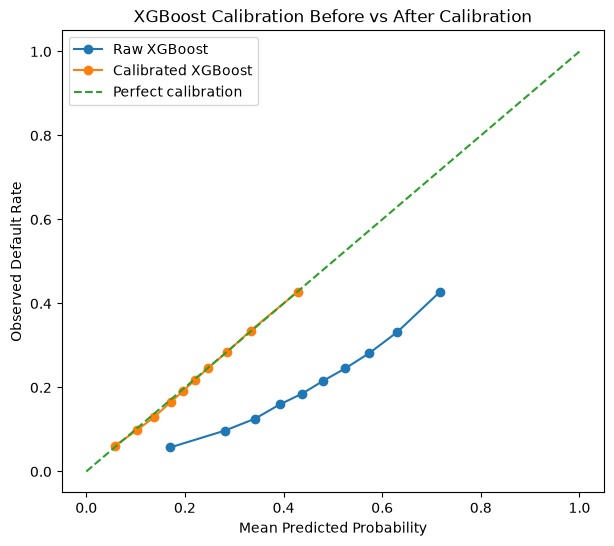

In [87]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

prob_true_raw, prob_pred_raw = calibration_curve(
    y_test,
    xgb_test_prob,
    n_bins=10,
    strategy="quantile"
)

prob_true_cal, prob_pred_cal = calibration_curve(
    y_test,
    xgb_test_calibrated,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 6))

plt.plot(
    prob_pred_raw,
    prob_true_raw,
    marker="o",
    label="Raw XGBoost"
)

plt.plot(
    prob_pred_cal,
    prob_true_cal,
    marker="o",
    label="Calibrated XGBoost"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Default Rate")
plt.title("XGBoost Calibration Before vs After Calibration")
plt.legend()
plt.show()

In [88]:
import pandas as pd
import numpy as np

risk_summary = pd.DataFrame({
    "actual_default": y_test.values,
    "predicted_pd": xgb_test_calibrated
})

print(risk_summary["predicted_pd"].describe())

print(
    risk_summary["predicted_pd"]
    .quantile([0, 0.1, 0.2, 0.4, 0.6, 0.8, 0.9, 1.0])
)

count    225277.000000
mean          0.215127
std           0.108292
min           0.000000
25%           0.138508
50%           0.208266
75%           0.282334
max           1.000000
Name: predicted_pd, dtype: float64
0.0    0.000000
0.1    0.077495
0.2    0.116619
0.4    0.184345
0.6    0.227293
0.8    0.307443
0.9    0.354404
1.0    1.000000
Name: predicted_pd, dtype: float64


In [89]:
risk_summary["risk_band"] = pd.cut(
    risk_summary["predicted_pd"],
    bins=[0, 0.10, 0.20, 0.30, 0.40, 1.0],
    labels=[
        "Very Low",
        "Low",
        "Medium",
        "High",
        "Very High"
    ],
    include_lowest=True
)

In [90]:
band_summary = (
    risk_summary
    .groupby("risk_band", observed=True)
    .agg(
        borrowers=("actual_default", "size"),
        predicted_pd=("predicted_pd", "mean"),
        observed_default_rate=("actual_default", "mean")
    )
)

band_summary["default_rate_pct"] = (
    band_summary["observed_default_rate"] * 100
)

band_summary["predicted_pd_pct"] = (
    band_summary["predicted_pd"] * 100
)

band_summary

,borrowers,predicted_pd,observed_default_rate,default_rate_pct,predicted_pd_pct
risk_band,,,,,
Very Low,35148,0.067415,0.069335,6.933538,6.741486
Low,77188,0.156618,0.150269,15.026947,15.661828
Medium,65861,0.247729,0.246018,24.601813,24.772879
High,33565,0.340959,0.344704,34.470431,34.095871
Very High,13515,0.462053,0.454976,45.497595,46.205273
